In [1]:
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub

# Download latest version
path = kagglehub.dataset_download("gregorut/videogamesales")

print("Path to dataset files:", path)

/kaggle/input/videogamesales/vgsales.csv
Path to dataset files: /kaggle/input/videogamesales


## 1. Understand the Problem

Define the task: Is it regression (predicting continuous values) or classification (predicting discrete labels)?
Ensure data contains input features (predictors) and target variable.

**Predict video game sales (Regression)**

Feature Selection helps eliminate irrelevant features to improve model efficiency and accuracy.

In [2]:
# Import helpful libraries
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

# Load the data, and separate the target
video_game_file_path = '/kaggle/input/videogamesales/vgsales.csv'
video_game_data = pd.read_csv(video_game_file_path)
X_test = pd.read_csv(video_game_file_path)

# Define target variable
y = video_game_data['Global_Sales']

# Create X with set of features
features = ['Name', 'Genre', 'Publisher', 'Year']
X = video_game_data[features]

#Train-Test Split: Split data into training and validation sets. 
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,
                                                                random_state=1)
categorical_cols = [cname for cname in X_train.columns if 
                    X_train[cname].dtype == "object"]
# Select numerical columns
numerical_cols = [cname for cname in X_train.columns if 
                X_train[cname].dtype in ['int64', 'float64']]
# Keep selected columns only
my_cols = categorical_cols + numerical_cols
X_train = X_train[my_cols].copy()
X_valid = X_valid[my_cols].copy()
X_test = X_test[my_cols].copy()

As we can see for year, there is a little correlation between year of release and global sales. The more into the future we go, the larger global sales occur.

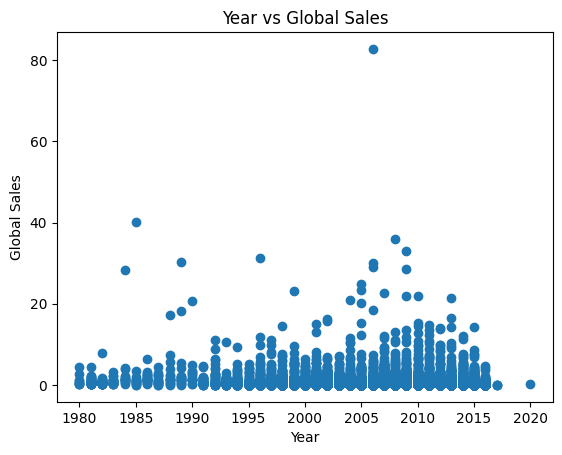

In [3]:
plt.scatter(video_game_data['Year'], video_game_data['Global_Sales'])
plt.xlabel("Year")
plt.ylabel("Global Sales")
plt.title("Year vs Global Sales")
plt.show()

For Genre, some genres specifically have higher global sales than other, which can help predict these sales.

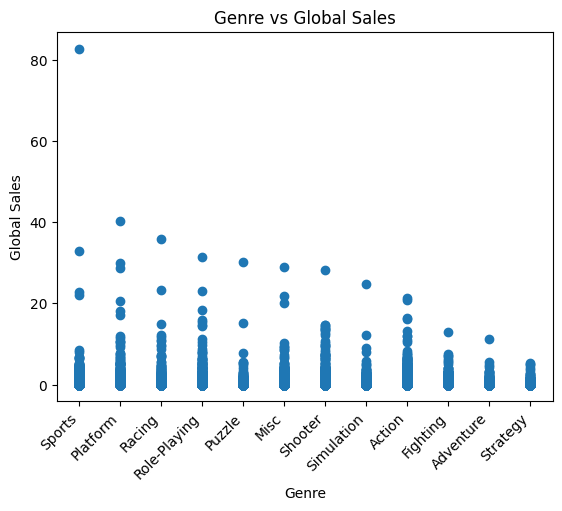

In [4]:
plt.scatter(video_game_data['Genre'], video_game_data['Global_Sales'])
plt.xlabel("Genre")
plt.ylabel("Global Sales")
plt.title("Genre vs Global Sales")
plt.xticks(rotation=45, ha='right')
plt.show()

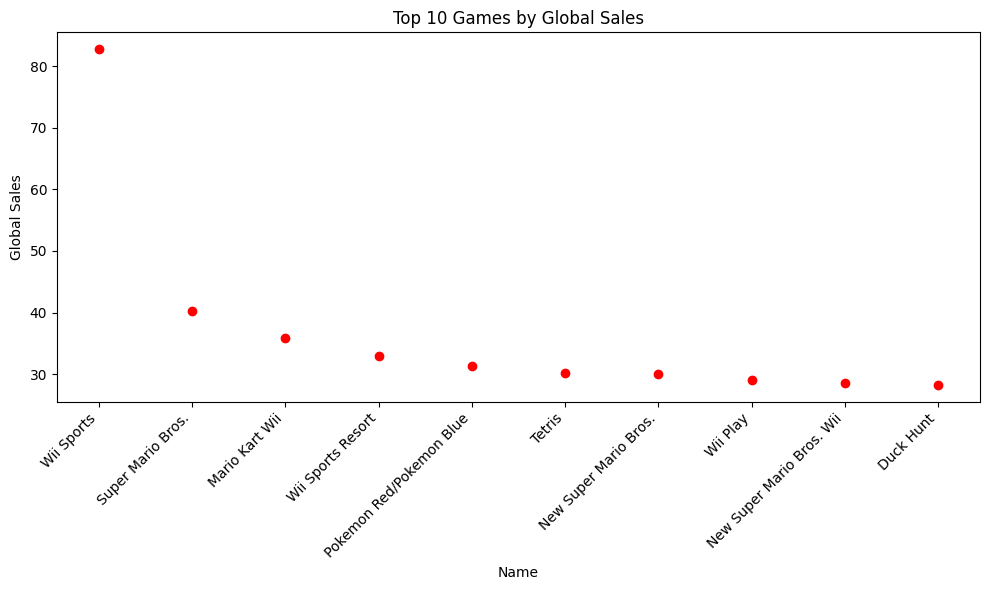

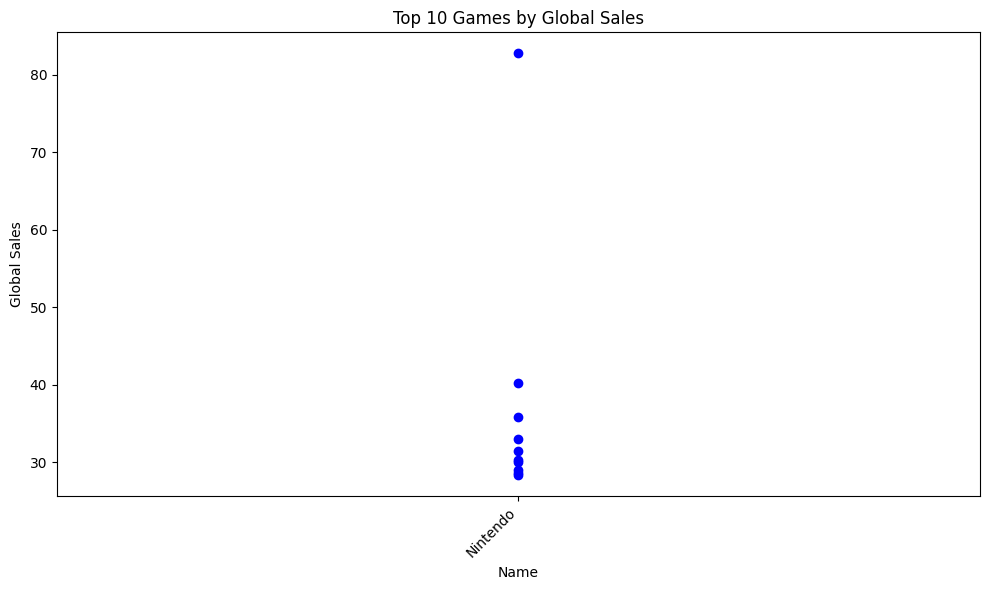

In [5]:
limited_data = video_game_data.nlargest(10, 'Global_Sales')
plt.figure(figsize=(10, 6))
plt.scatter(limited_data['Name'], limited_data['Global_Sales'], color='red')
plt.xlabel("Name")
plt.ylabel("Global Sales")
plt.title("Top 10 Games by Global Sales")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

limited_data = video_game_data.nlargest(10, 'Global_Sales')
plt.figure(figsize=(10, 6))
plt.scatter(limited_data['Publisher'], limited_data['Global_Sales'], color='blue')
plt.xlabel("Name")
plt.ylabel("Global Sales")
plt.title("Top 10 Games by Global Sales")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

It would appear that the top 10 games with the highest global sales all seem to be published by Nintendo. This shows that using publisher as a feature can significantly help to determine the global sales of a game.

## 2. Data Preprocessing

In [6]:
# Categorical columns in the training data
categorical_cols = [col for col in X_train.columns if X_train[col].dtype == "object"]

### Ordinal Encoding
Here I have chosen to Ordinal encoding rather than use One Hot encoding to reduce the amount of code I need to use. Despite One Hot encoding being more efficient, using Ordinal encoding keeps my code simple and easy to understand for a small-size model such as this.


In [7]:
from sklearn.preprocessing import OrdinalEncoder

# Apply ordinal encoder 
ordinal_encoder = OrdinalEncoder()
X_train[categorical_cols] = ordinal_encoder.fit_transform(X_train[categorical_cols])
X_valid[categorical_cols] = ordinal_encoder.fit_transform(X_valid[categorical_cols])

### Imputing
Removing columns with Nan from my dataset would severly limit my options for feature selection, thus making imputing the best option available

In [8]:
#Impute
from sklearn.impute import SimpleImputer

# Imputation
my_imputer = SimpleImputer()
imputed_X_train = pd.DataFrame(my_imputer.fit_transform(X_train))
imputed_X_valid = pd.DataFrame(my_imputer.fit_transform(X_valid))

# Imputation removed column names; put them back
imputed_X_train.columns = X_train.columns
imputed_X_valid.columns = X_valid.columns
X_train = imputed_X_train
X_valid = imputed_X_valid

print(X_train.columns)

Index(['Name', 'Genre', 'Publisher', 'Year'], dtype='object')


Constructing and fitting models for random forest and decision tree respectively for feature importance modelling.

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

# Random forest model
rt_vg_model = RandomForestRegressor(random_state=1, n_estimators=100, max_depth=3)
rt_vg_model.fit(X_train, y_train)

# Decision tree model
dt_vg_model = DecisionTreeRegressor(random_state=1, max_depth=3)
dt_vg_model.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=3, random_state=1)

## 3. Model Building & Training

### Selecting the model: Decision tree or Random Forest
For the model, I will be using both decision tree and random forest to compare their respective MAEs later.
### Hyperparameters
* random_state:
1 for consistency
* max_depth:
Increasing the number of estimators usually improves the model's performance up to a point because more trees reduce variance.
* n_estimators:
Depth 3 ensures that each tree can only split the data three times, simplifying the model and reducing the risk of overfitting in the training data.
* max_leaf_nodes:
This value will remain 10 however, is very likely to change in optimization.

All of these hyperparameters are temporary until the most optimal ones can be found in 4. Model Evaluation.

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

# Random forest model
rt_vg_model = RandomForestRegressor(random_state=1, n_estimators=100, max_depth=3)
rt_vg_model.fit(X_train, y_train)

# Decision tree model
dt_vg_model = DecisionTreeRegressor(random_state=1, max_depth=3, max_leaf_nodes=10)
dt_vg_model.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=3, max_leaf_nodes=10, random_state=1)

## 4. Model Evaluation - Evaluate on the training and validation data
Training each respective model on the training and validation data and testing what hyperparameters work out the best.

In [11]:
rt_vg_model = RandomForestRegressor(n_estimators=100, max_depth=3, random_state=1)
rt_vg_model.fit(X_train, y_train)

dt_vg_model = DecisionTreeRegressor(max_leaf_nodes=50, max_depth=3, random_state=1)
dt_vg_model.fit(X_train, y_train)

# Make predictions
rt_y_train_pred = rt_vg_model.predict(X_train)

# Make predictions
dt_y_train_pred = dt_vg_model.predict(X_train)

# Evaluate the model (Random Forest Regressor)
train_mae = mean_absolute_error(y_train, rt_y_train_pred)

print("Random Forest Regressor MAE:")
print(f"Training MAE: {train_mae:.2f}")

# Evaluate the model (Decision Tree)
train_mae = mean_absolute_error(y_train, dt_y_train_pred)

print("Decision Tree MAE:")
print(f"Training MAE: {train_mae:.2f}")

Random Forest Regressor MAE:
Training MAE: 0.55
Decision Tree MAE:
Training MAE: 0.56


Decision Tree model appears to produce a lower MAE than the Random Forest Regressor.

### Random Forest

In [12]:
#Target variable distribution
print(y_train.describe())
print(y_valid.describe())

# Compare a sample of predictions with actual values
print("Sample Predictions vs Actuals:")
print(f"Predictions: {rt_y_train_pred[:10]}")
print(f"Actuals: {y_valid[:10]}")

count    13278.000000
mean         0.534747
std          1.581136
min          0.010000
25%          0.060000
50%          0.170000
75%          0.470000
max         82.740000
Name: Global_Sales, dtype: float64
count    3320.000000
mean        0.548214
std         1.446081
min         0.010000
25%         0.060000
50%         0.170000
75%         0.480000
max        31.370000
Name: Global_Sales, dtype: float64
Sample Predictions vs Actuals:
Predictions: [0.47530418 0.46117549 0.32909882 0.47667075 0.54083212 0.403694
 0.39271114 0.55471076 0.55471076 0.55471076]
Actuals: 4234     0.46
7119     0.23
106      7.13
5242     0.36
13547    0.04
11608    0.08
8750     0.15
3603     0.56
10652    0.10
5190     0.36
Name: Global_Sales, dtype: float64


### Decision Tree

In [13]:
#Target variable distribution
print(y_train.describe())
print(y_valid.describe())

# Compare a sample of predictions with actual values
print("Sample Predictions vs Actuals:")
print(f"Predictions: {dt_y_train_pred[:10]}")
print(f"Actuals: {y_valid[:10]}")

count    13278.000000
mean         0.534747
std          1.581136
min          0.010000
25%          0.060000
50%          0.170000
75%          0.470000
max         82.740000
Name: Global_Sales, dtype: float64
count    3320.000000
mean        0.548214
std         1.446081
min         0.010000
25%         0.060000
50%         0.170000
75%         0.480000
max        31.370000
Name: Global_Sales, dtype: float64
Sample Predictions vs Actuals:
Predictions: [0.46625    0.46625    0.33797989 0.46625    0.54347691 0.33797989
 0.33797989 0.54347691 0.54347691 0.54347691]
Actuals: 4234     0.46
7119     0.23
106      7.13
5242     0.36
13547    0.04
11608    0.08
8750     0.15
3603     0.56
10652    0.10
5190     0.36
Name: Global_Sales, dtype: float64


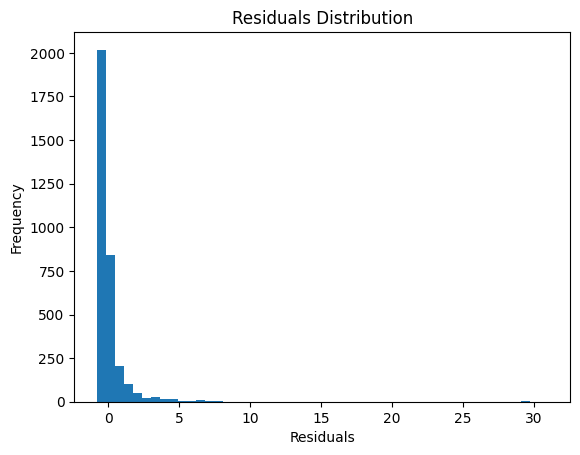

In [14]:
residuals = y_valid - rt_vg_model.predict(X_valid)

plt.hist(residuals, bins=50)
plt.title("Residuals Distribution")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

The Random Forest Regressor model is skewed a lot to the right.

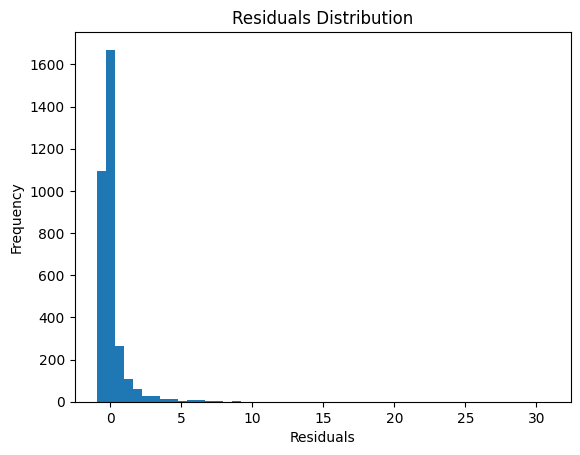

In [15]:
residuals = y_valid - dt_vg_model.predict(X_valid)
plt.hist(residuals, bins=50)
plt.title("Residuals Distribution")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

The decision tree model is skewed to the right but not as far as random forest.

Residuals are the differences between the observed values and the predicted values. A normal distribution of errors is indicitive of a well-fitted model where errors are randomly distributed.

## Underfitting or Overfitting
It appears both of the models are underfitting due to the lack of optimization and more importantly lack of features available.

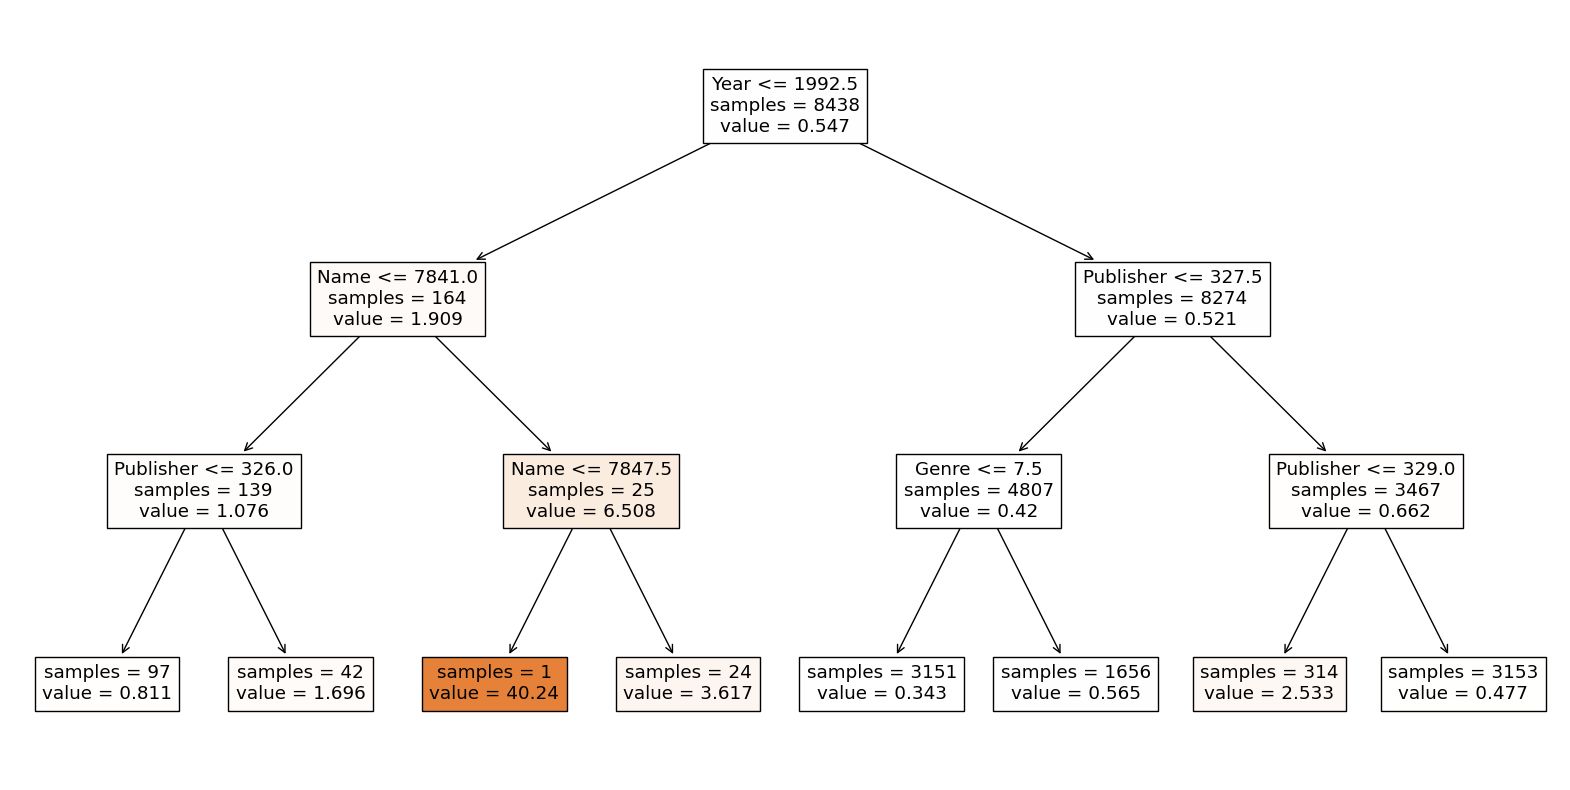

In [16]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Extract the first tree from the random forest
tree = rt_vg_model.estimators_[0]

# Visualize the tree
plt.figure(figsize=(20, 10))
plot_tree(tree, 
          feature_names=X_train.columns, impurity=False, filled=True)
plt.show()

Here we'll optimize the models and predictions.

In [17]:
rt_vg_model = RandomForestRegressor(n_estimators=50, max_depth=100, random_state=1)
rt_vg_model.fit(X_train, y_train)

dt_vg_model = DecisionTreeRegressor(max_depth=80, random_state=1, max_leaf_nodes=300)
dt_vg_model.fit(X_train, y_train)

# Make predictions
rt_y_train_pred = rt_vg_model.predict(X_train)

# Make predictions
dt_y_train_pred = dt_vg_model.predict(X_train)

# Evaluate the model (Random Forest Regressor)
train_mae = mean_absolute_error(y_train, rt_y_train_pred)

print("Random Forest Regressor MAE:")
print(f"Training MAE: {train_mae:.2f}")

# Evaluate the model (Decision Tree)
train_mae = mean_absolute_error(y_train, dt_y_train_pred)

print("Decision Tree MAE:")
print(f"Training MAE: {train_mae:.2f}")

Random Forest Regressor MAE:
Training MAE: 0.21
Decision Tree MAE:
Training MAE: 0.34


For the decision tree the best MAE I could achieve without overfitting and maintaining a normal residuals distribution was 0.34 while for random forest regressor, I could get it down to 0.21

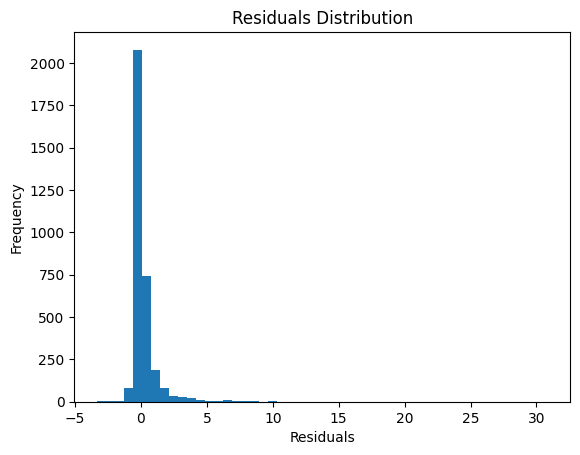

In [18]:
residuals = y_valid - rt_vg_model.predict(X_valid)
plt.hist(residuals, bins=50)
plt.title("Residuals Distribution")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

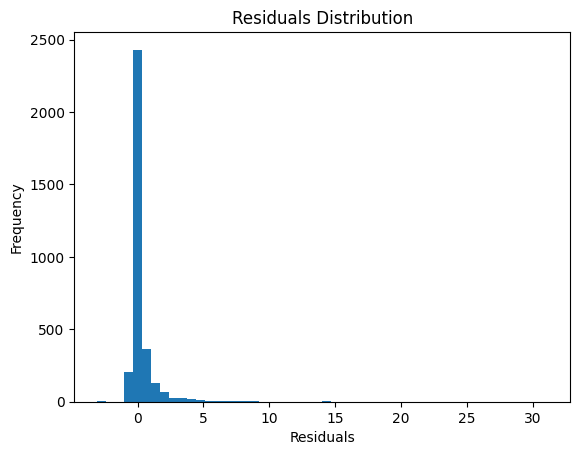

In [19]:
residuals = y_valid - dt_vg_model.predict(X_valid)
plt.hist(residuals, bins=50)
plt.title("Residuals Distribution")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

## 5. Model Interpretation

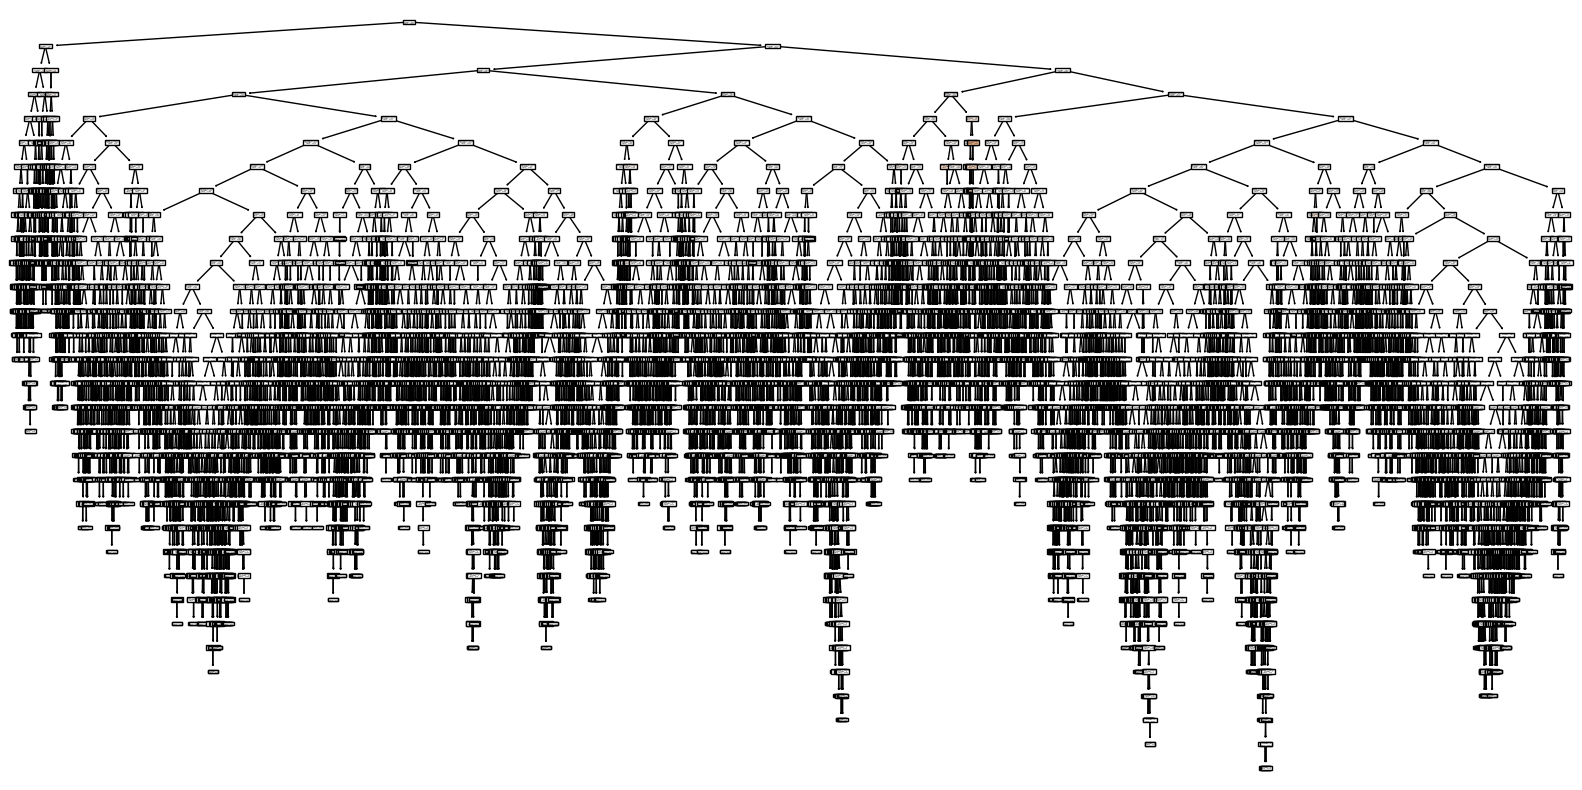

In [20]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Extract the first tree from the random forest
tree = rt_vg_model.estimators_[0]

# Visualize the tree
plt.figure(figsize=(20, 10))
plot_tree(tree, 
          feature_names=X_train.columns, impurity=False, filled=True)
plt.show()


### Plotting Feature Importance

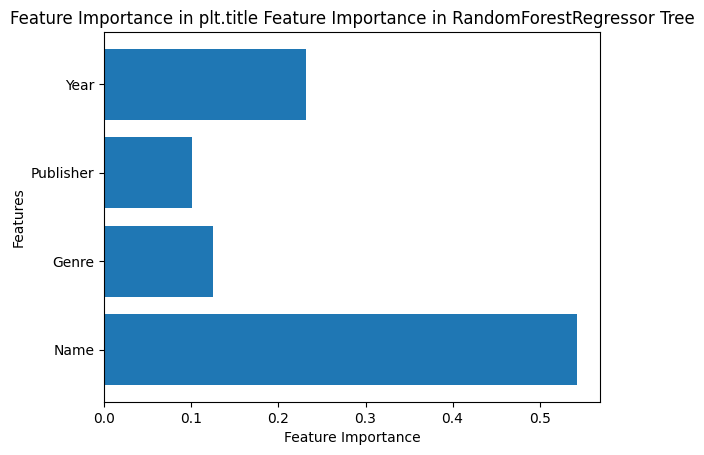

In [21]:
# Plot feature importance
feature_importances = rt_vg_model.feature_importances_
features = np.array(X_train.columns)

plt.barh(features, feature_importances)
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Feature Importance in plt.title Feature Importance in RandomForestRegressor Tree")
plt.show()

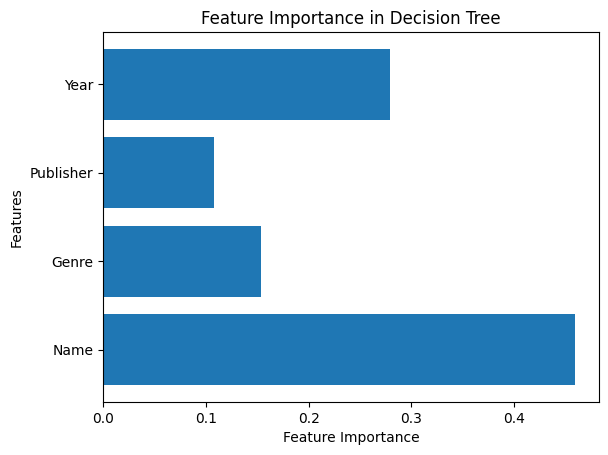

In [22]:
# Plot feature importance
feature_importances = dt_vg_model.feature_importances_
features = np.array(X_train.columns)

plt.barh(features, feature_importances)
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Feature Importance in Decision Tree")
plt.show()

## 6. Some possible extensions (Bonus)

## Pipeline

In [23]:
#Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Preprocessing for numerical data
numerical_transformer = SimpleImputer(strategy='constant')

# Preprocessing for categorical data
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Bundle preprocessing for numerical and categorical data
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

In [24]:
rt_vg_model = RandomForestRegressor(n_estimators=50, max_depth=100, random_state=1)
rt_vg_model.fit(X_train, y_train)

rf_valid_predictions = rt_vg_model.predict(X_valid)

print(f"Pipeline MAE: {train_mae:.2f}")

Pipeline MAE: 0.34
